# Description de la problématique

# Préambule: Import des librairies

In [1]:
import sys
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, roc_auc_score, classification_report, confusion_matrix

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

Python: 3.11.17
Platform: macOS-27.0.1-arm64-arm-64bit
NumPy: 2.4.6
Pandas: 3.1.1
Scikit-learn: 1.9.1


# 1. Collecte des données
On utilise un dataset issu de réservations de 2 hôtels situés au Portugal:

https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand

## 1.1. Chargement des données
Chargement du dataset dans un dataframe Pandas et copie dans un dataframe de travail

In [2]:
df_original = pd.read_csv("input/hotel_bookings.csv")
df = df_original.copy()
print("Nombre de réservations (lignes):",df.shape[0])
print("Nombre de caractéristiques (colonnes):",df.shape[1])

Nombre de réservations (lignes): 119390
Nombre de caractéristiques (colonnes): 32


## 1.2. Aperçu des données

In [3]:
print("\n--- Aperçu des données ---")
display(df.head())

print("\nTypes des colonnes:")
df.info()


--- Aperçu des données ---


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03



Types des colonnes:
<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal  

## 1.3. Nomenclature des colonnes
Le modèle doit apprendre à prévoir le risque d'annulation d'une réservation, c'est la colonne "is_canceled" qui indique si la réservation a été annulée (1) ou honorée (0), ça sera notre variable cible pour l'apprentissage.

<table cellspacing="0" border="0">
	<colgroup width="221"></colgroup>
	<colgroup width="226"></colgroup>
	<colgroup width="143"></colgroup>
	<colgroup width="423"></colgroup>
	<tr>
		<td colspan=2 height="27" align="left" valign=bottom bgcolor="#1D2330" sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Glossaire des champs — hotel_bookings&quot;}"><b><font face="Liberation Serif" size=4 color="#FFFFFF">Glossaire des champs — hotel_bookings</font></b></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
	</tr>
	<tr>
		<td colspan=2 height="20" align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#666666"><br></font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
	</tr>
	<tr>
		<td height="45" align="left" valign=bottom bgcolor="#D9EAF7" sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Caractéristique&quot;}"><b><font face="Liberation Serif" color="#000000">Caractéristique</font></b></td>
		<td align="left" valign=bottom bgcolor="#D9EAF7" sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Description&quot;}"><b><font face="Liberation Serif" color="#000000">Description</font></b></td>
		<td align="left" valign=bottom bgcolor="#D9EAF7" sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Valeurs \/ critères possibles&quot;}"><b><font face="Liberation Serif" color="#000000">Valeurs / critères possibles</font></b></td>
		<td align="left" valign=bottom bgcolor="#D9EAF7" sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Explication des valeurs&quot;}"><b><font face="Liberation Serif" color="#000000">Explication des valeurs</font></b></td>
	</tr>
	<tr>
		<td height="46" align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;hotel&quot;}"><font face="Liberation Serif" color="#000000">hotel</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Hotel urbain ou resort Hotel &quot;}"><font face="Liberation Serif" color="#000000">Hotel urbain ou resort Hotel </font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;City Hotel, Resort Hotel&quot;}"><font face="Liberation Serif" color="#000000">City Hotel, Resort Hotel</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;City Hotel : hôtel situé en zone urbaine. Resort Hotel : hôtel de villégiature, généralement orienté loisirs et séjours de détente.&quot;}"><font face="Liberation Serif" color="#000000">City Hotel : hôtel situé en zone urbaine. Resort Hotel : hôtel de villégiature, généralement orienté loisirs et séjours de détente.</font></td>
	</tr>
	<tr>
		<td height="40" align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;is_canceled&quot;}"><font face="Liberation Serif" color="#000000">is_canceled</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Indique si la réservation a été annulée (0 = non, 1 = oui).&quot;}"><font face="Liberation Serif" color="#000000">Indique si la réservation a été annulée (0 = non, 1 = oui).</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;0, 1&quot;}"><font face="Liberation Serif" color="#000000">0, 1</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;0 : réservation non annulée. 1 : réservation annulée.&quot;}"><font face="Liberation Serif" color="#000000">0 : réservation non annulée. 1 : réservation annulée.</font></td>
	</tr>
	<tr>
		<td height="41" align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;lead_time&quot;}"><font face="Liberation Serif" color="#000000">lead_time</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Nombre de jours entre la réservation et la date d'arrivée.&quot;}"><font face="Liberation Serif" color="#000000">Nombre de jours entre la réservation et la date d'arrivée.</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
	</tr>
	<tr>
		<td height="28" align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;arrival_date_year&quot;}"><font face="Liberation Serif" color="#000000">arrival_date_year</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Année prévue d'arrivée du client.&quot;}"><font face="Liberation Serif" color="#000000">Année prévue d'arrivée du client.</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
	</tr>
	<tr>
		<td height="138" align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;arrival_date_month&quot;}"><font face="Liberation Serif" color="#000000">arrival_date_month</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Mois prévu d'arrivée du client.&quot;}"><font face="Liberation Serif" color="#000000">Mois prévu d'arrivée du client.</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot; 'January',  'February',     'March',     'April',       'May',      'June', 'July',    'August', 'September',   'October',  'November',  'December',   &quot;}"><font face="Liberation Serif" color="#000000"> 'January',  'February',     'March',     'April',       'May',      'June', 'July',    'August', 'September',   'October',  'November',  'December',   </font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
	</tr>
	<tr>
		<td height="43" align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;arrival_date_week_number&quot;}"><font face="Liberation Serif" color="#000000">arrival_date_week_number</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Numéro de la semaine calendaire prévue pour l'arrivée.&quot;}"><font face="Liberation Serif" color="#000000">Numéro de la semaine calendaire prévue pour l'arrivée.</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
	</tr>
	<tr>
		<td height="26" align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;arrival_date_day_of_month&quot;}"><font face="Liberation Serif" color="#000000">arrival_date_day_of_month</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Jour du mois prévu pour l'arrivée.&quot;}"><font face="Liberation Serif" color="#000000">Jour du mois prévu pour l'arrivée.</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
	</tr>
	<tr>
		<td height="45" align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;stays_in_weekend_nights&quot;}"><font face="Liberation Serif" color="#000000">stays_in_weekend_nights</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Nombre de nuits du séjour qui tombent un week-end.&quot;}"><font face="Liberation Serif" color="#000000">Nombre de nuits du séjour qui tombent un week-end.</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
	</tr>
	<tr>
		<td height="44" align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;stays_in_week_nights&quot;}"><font face="Liberation Serif" color="#000000">stays_in_week_nights</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Nombre de nuits du séjour qui tombent en semaine.&quot;}"><font face="Liberation Serif" color="#000000">Nombre de nuits du séjour qui tombent en semaine.</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
	</tr>
	<tr>
		<td height="42" align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;adults&quot;}"><font face="Liberation Serif" color="#000000">adults</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Nombre d'adultes inclus dans la réservation.&quot;}"><font face="Liberation Serif" color="#000000">Nombre d'adultes inclus dans la réservation.</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
	</tr>
	<tr>
		<td height="42" align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;children&quot;}"><font face="Liberation Serif" color="#000000">children</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Nombre d'enfants inclus dans la réservation.&quot;}"><font face="Liberation Serif" color="#000000">Nombre d'enfants inclus dans la réservation.</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
	</tr>
	<tr>
		<td height="40" align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;babies&quot;}"><font face="Liberation Serif" color="#000000">babies</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Nombre de bébés inclus dans la réservation.&quot;}"><font face="Liberation Serif" color="#000000">Nombre de bébés inclus dans la réservation.</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
	</tr>
	<tr>
		<td height="49" align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;meal&quot;}"><font face="Liberation Serif" color="#000000">meal</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Type de formule de restauration associé à la réservation.&quot;}"><font face="Liberation Serif" color="#000000">Type de formule de restauration associé à la réservation.</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;'BB', 'FB', 'HB', 'SC', 'Undefined'&quot;}"><font face="Liberation Serif" color="#000000">'BB', 'FB', 'HB', 'SC', 'Undefined'</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
	</tr>
	<tr>
		<td height="43" align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;country&quot;}"><font face="Liberation Serif" color="#000000">country</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Code du pays de résidence du client.&quot;}"><font face="Liberation Serif" color="#000000">Code du pays de résidence du client.</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
	</tr>
	<tr>
		<td height="139" align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;market_segment&quot;}"><font face="Liberation Serif" color="#000000">market_segment</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Segment commercial auquel appartient la réservation.&quot;}"><font face="Liberation Serif" color="#000000">Segment commercial auquel appartient la réservation.</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Aviation, Complementary, Corporate, Direct, Groups, Offline TA\/TO, Online TA, Undefined&quot;}"><font face="Liberation Serif" color="#000000">Aviation, Complementary, Corporate, Direct, Groups, Offline TA/TO, Online TA, Undefined</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Aviation : compagnies aériennes bénéficiant d'un accord pour l'hébergement de son personnel de bord. Complementary : séjour ou réservation offerte. Corporate : clientèle d'entreprise. Direct : réservation effectuée directement auprès de l'hôtel. Groups : réservation de groupe. Offline TA\/TO : agence de voyages ou tour-opérateur utilisant un canal hors ligne. Online TA : agence de voyages ou tour-opérateur en ligne. Undefined : segment non défini ou non renseigné.&quot;}"><font face="Liberation Serif" color="#000000">Aviation : compagnies aériennes bénéficiant d'un accord pour l'hébergement de son personnel de bord. Complementary : séjour ou réservation offerte. Corporate : clientèle d'entreprise. Direct : réservation effectuée directement auprès de l'hôtel. Groups : réservation de groupe. Offline TA/TO : agence de voyages ou tour-opérateur utilisant un canal hors ligne. Online TA : agence de voyages ou tour-opérateur en ligne. Undefined : segment non défini ou non renseigné.</font></td>
	</tr>
	<tr>
		<td height="130" align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;distribution_channel&quot;}"><font face="Liberation Serif" color="#000000">distribution_channel</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Canal par lequel la réservation a été réalisée.&quot;}"><font face="Liberation Serif" color="#000000">Canal par lequel la réservation a été réalisée.</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Corporate, Direct, GDS, TA\/TO, Undefined&quot;}"><font face="Liberation Serif" color="#000000">Corporate, Direct, GDS, TA/TO, Undefined</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Corporate : canal associé aux réservations d'entreprise sous contrat négocié (généralement avec Carte de Crédit fournie pour garantie, modifiable ou remboursable sous conditions). Direct : réservation directe auprès de l'hôtel. GDS : système mondial de distribution utilisé par les intermédiaires du voyage. TA\/TO : agence de voyages ou tour-opérateur. Undefined : canal non défini ou non renseigné.&quot;}"><font face="Liberation Serif" color="#000000">Corporate : canal associé aux réservations d'entreprise sous contrat négocié (généralement avec Carte de Crédit fournie pour garantie, modifiable ou remboursable sous conditions). Direct : réservation directe auprès de l'hôtel. GDS : système mondial de distribution utilisé par les intermédiaires du voyage. TA/TO : agence de voyages ou tour-opérateur. Undefined : canal non défini ou non renseigné.</font></td>
	</tr>
	<tr>
		<td height="46" align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;is_repeated_guest&quot;}"><font face="Liberation Serif" color="#000000">is_repeated_guest</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Indique si le client a déjà séjourné dans l'hôtel (0 = non, 1 = oui).&quot;}"><font face="Liberation Serif" color="#000000">Indique si le client a déjà séjourné dans l'hôtel (0 = non, 1 = oui).</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
	</tr>
	<tr>
		<td height="44" align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;previous_cancellations&quot;}"><font face="Liberation Serif" color="#000000">previous_cancellations</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Nombre de réservations antérieures annulées par le client.&quot;}"><font face="Liberation Serif" color="#000000">Nombre de réservations antérieures annulées par le client.</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
	</tr>
	<tr>
		<td height="47" align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;previous_bookings_not_canceled&quot;}"><font face="Liberation Serif" color="#000000">previous_bookings_not_canceled</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Nombre de réservations antérieures du client qui n'ont pas été annulées.&quot;}"><font face="Liberation Serif" color="#000000">Nombre de réservations antérieures du client qui n'ont pas été annulées.</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
	</tr>
	<tr>
		<td height="214" align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;reserved_room_type&quot;}"><font face="Liberation Serif" color="#000000">reserved_room_type</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Type de chambre demandé lors de la réservation.&quot;}"><font face="Liberation Serif" color="#000000">Type de chambre demandé lors de la réservation.</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;A, B, C, D, E, F, G, H, L, P&quot;}"><font face="Liberation Serif" color="#000000">A, B, C, D, E, F, G, H, L, P</font></td>
		<td rowspan=2 align="left" valign=middle data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;A : AAA discount available (Réduction partenaire (type club AAA) disponible)\nB : Complementary breakfast (Petit-déjeuner offert \/ inclus)\nC : Complementary coffee (Café offert)\nD : Complementary evening cocktail (Cocktail de soirée offert)\nE : European style hotel (Hôtel de style européen)\nF : Free local phone calls (Appels téléphoniques locaux gratuits)\nG : Parking available (Parking disponible)\nH : Health facilities (Accès gratuit aux installations de sport \/ bien-être)\nI : In-room appliances (Équipements en chambre - cafetière, fer à repasser, sèche-cheveux)\nK : Kitchen facilities (Cuisine ou kitchenette disponible)\nL : Local transportation shuttle (Navette de transport locale gratuite)\nP : Indoor Pool (Piscine intérieure \/ couverte) Correspondent aux différents types de chambres définis dans le système. Le type attribué peut différer du type réservé.&quot;}"><font face="Liberation Serif" color="#000000">A : AAA discount available (Réduction partenaire (type club AAA) disponible)<br>B : Complementary breakfast (Petit-déjeuner offert / inclus)<br>C : Complementary coffee (Café offert)<br>D : Complementary evening cocktail (Cocktail de soirée offert)<br>E : European style hotel (Hôtel de style européen)<br>F : Free local phone calls (Appels téléphoniques locaux gratuits)<br>G : Parking available (Parking disponible)<br>H : Health facilities (Accès gratuit aux installations de sport / bien-être)<br>I : In-room appliances (Équipements en chambre - cafetière, fer à repasser, sèche-cheveux)<br>K : Kitchen facilities (Cuisine ou kitchenette disponible)<br>L : Local transportation shuttle (Navette de transport locale gratuite)<br>P : Indoor Pool (Piscine intérieure / couverte) Correspondent aux différents types de chambres définis dans le système. Le type attribué peut différer du type réservé.</font></td>
	</tr>
	<tr>
		<td height="82" align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;assigned_room_type&quot;}"><font face="Liberation Serif" color="#000000">assigned_room_type</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Type de chambre finalement attribué au client.&quot;}"><font face="Liberation Serif" color="#000000">Type de chambre finalement attribué au client.</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;A, B, C, D, E, F, G, H, I, K, L, P&quot;}"><font face="Liberation Serif" color="#000000">A, B, C, D, E, F, G, H, I, K, L, P</font></td>
		</tr>
	<tr>
		<td height="53" align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;booking_changes&quot;}"><font face="Liberation Serif" color="#000000">booking_changes</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Nombre de modifications apportées à la réservation après sa création.&quot;}"><font face="Liberation Serif" color="#000000">Nombre de modifications apportées à la réservation après sa création.</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
	</tr>
	<tr>
		<td height="72" align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;deposit_type&quot;}"><font face="Liberation Serif" color="#000000">deposit_type</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Type de garantie ou de dépôt demandé pour la réservation.&quot;}"><font face="Liberation Serif" color="#000000">Type de garantie ou de dépôt demandé pour la réservation.</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;No Deposit, Non Refund, Refundable&quot;}"><font face="Liberation Serif" color="#000000">No Deposit, Non Refund, Refundable</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;No Deposit : aucun dépôt ou acompte demandé. Non Refund : réservation non remboursable, généralement avec paiement ou garantie préalable. Refundable : réservation associée à une garantie ou à un dépôt remboursable selon les conditions applicables.&quot;}"><font face="Liberation Serif" color="#000000">No Deposit : aucun dépôt ou acompte demandé. Non Refund : réservation non remboursable, généralement avec paiement ou garantie préalable. Refundable : réservation associée à une garantie ou à un dépôt remboursable selon les conditions applicables.</font></td>
	</tr>
	<tr>
		<td height="68" align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;agent&quot;}"><font face="Liberation Serif" color="#000000">agent</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Identifiant de l'agence de voyages ou de l'agent ayant effectué la réservation.&quot;}"><font face="Liberation Serif" color="#000000">Identifiant de l'agence de voyages ou de l'agent ayant effectué la réservation.</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
	</tr>
	<tr>
		<td height="48" align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;company&quot;}"><font face="Liberation Serif" color="#000000">company</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Identifiant de l'entreprise associée à la réservation, le cas échéant.&quot;}"><font face="Liberation Serif" color="#000000">Identifiant de l'entreprise associée à la réservation, le cas échéant.</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
	</tr>
	<tr>
		<td height="55" align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;days_in_waiting_list&quot;}"><font face="Liberation Serif" color="#000000">days_in_waiting_list</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Nombre de jours pendant lesquels la réservation a été en attente avant confirmation.&quot;}"><font face="Liberation Serif" color="#000000">Nombre de jours pendant lesquels la réservation a été en attente avant confirmation.</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
	</tr>
	<tr>
		<td height="77" align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;customer_type&quot;}"><font face="Liberation Serif" color="#000000">customer_type</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Catégorie de client selon son profil ou le contexte de réservation.&quot;}"><font face="Liberation Serif" color="#000000">Catégorie de client selon son profil ou le contexte de réservation.</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Contract, Group, Transient, Transient-Party&quot;}"><font face="Liberation Serif" color="#000000">Contract, Group, Transient, Transient-Party</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Contract : réservation liée à un contrat négocié. Group : réservation appartenant à un groupe. Transient : client individuel, hors contrat ou groupe. Transient-Party : réservation individuelle rattachée à un petit groupe ou à une party.&quot;}"><font face="Liberation Serif" color="#000000">Contract : réservation liée à un contrat négocié. Group : réservation appartenant à un groupe. Transient : client individuel, hors contrat ou groupe. Transient-Party : réservation individuelle rattachée à un petit groupe ou à une party.</font></td>
	</tr>
	<tr>
		<td height="51" align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;adr&quot;}"><font face="Liberation Serif" color="#000000">adr</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Average Daily Rate : tarif journalier moyen par chambre occupée et par nuit.&quot;}"><font face="Liberation Serif" color="#000000">Average Daily Rate : tarif journalier moyen par chambre occupée et par nuit.</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
	</tr>
	<tr>
		<td height="46" align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;required_car_parking_spaces&quot;}"><font face="Liberation Serif" color="#000000">required_car_parking_spaces</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Nombre de places de parking demandées par le client.&quot;}"><font face="Liberation Serif" color="#000000">Nombre de places de parking demandées par le client.</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
	</tr>
	<tr>
		<td height="50" align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;total_of_special_requests&quot;}"><font face="Liberation Serif" color="#000000">total_of_special_requests</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Nombre total de demandes particulières formulées par le client.&quot;}"><font face="Liberation Serif" color="#000000">Nombre total de demandes particulières formulées par le client.</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
	</tr>
	<tr>
		<td height="50" align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;reservation_status&quot;}"><font face="Liberation Serif" color="#000000">reservation_status</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;État final ou actuel de la réservation.&quot;}"><font face="Liberation Serif" color="#000000">État final ou actuel de la réservation.</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Canceled, Check-Out, No-Show&quot;}"><font face="Liberation Serif" color="#000000">Canceled, Check-Out, No-Show</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Canceled : réservation annulée. Check-Out : client ayant effectué son départ, séjour terminé. No-Show : client ne s'étant pas présenté sans annuler la réservation.&quot;}"><font face="Liberation Serif" color="#000000">Canceled : réservation annulée. Check-Out : client ayant effectué son départ, séjour terminé. No-Show : client ne s'étant pas présenté sans annuler la réservation.</font></td>
	</tr>
	<tr>
		<td height="50" align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;reservation_status_date&quot;}"><font face="Liberation Serif" color="#000000">reservation_status_date</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;Date à laquelle le statut de la réservation a été enregistré ou mis à jour pour la dernière fois.&quot;}"><font face="Liberation Serif" color="#000000">Date à laquelle le statut de la réservation a été enregistré ou mis à jour pour la dernière fois.</font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
		<td align="left" valign=bottom sdnum="1036;0;@" data-sheets-value="{ &quot;1&quot;: 2, &quot;2&quot;: &quot;&quot;}"><font face="Liberation Serif" color="#000000"><br></font></td>
	</tr>
</table>


# 2. Exploration et nettoyage des données

## 2.1. Suppression des caractéristiques non pertinentes
- La colonne "arrival_date_year" de doit pas influencer le modèle, car on n'aura pas cette notion d'antériorité au moment de la prédiction
- Les valeurs dans les colonnes: "assigned_room_type", "booking_changes", "reservation_status", "reservation_status_date" peuvent avoir été modifiées après qu'une réservation soit honorée, donc on n'en tiendra pas compte dans l'apprentissage afin d'éviter un "data leak"


In [4]:
# Colonnes à supprimer du dataset
df = df.drop(['arrival_date_year',
              'assigned_room_type', 'booking_changes', 'reservation_status', 'reservation_status_date'
	      ], 
	      axis = 1)


## 2.2. Identification des caractéristiques numériques et catégorielles

In [5]:
print("\nStatistiques descriptives numériques:")
display(df[df.select_dtypes(include=['number']).columns].describe(include='all'))

print("\nStatistiques descriptives catégorielles:")
display(df[df.select_dtypes(exclude=['number']).columns].describe(include='all'))

print("\nValeurs uniques des colonnes catégorielles:")
for col in df.select_dtypes(exclude=['number']).columns:
    print(f"{col}: \n{df[col].unique()}\n")



Statistiques descriptives numériques:


,is_canceled,lead_time,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000



Statistiques descriptives catégorielles:


,hotel,arrival_date_month,meal,country,market_segment,distribution_channel,reserved_room_type,deposit_type,customer_type
count,119390,119390,119390,118902,119390,119390,119390,119390,119390
unique,2,12,5,177,8,5,10,3,4
top,City Hotel,August,BB,PRT,Online TA,TA/TO,A,No Deposit,Transient
freq,79330,13877,92310,48590,56477,97870,85994,104641,89613



Valeurs uniques des colonnes catégorielles:
hotel: 
<StringArray>
['Resort Hotel', 'City Hotel']
Length: 2, dtype: str

arrival_date_month: 
<StringArray>
[     'July',    'August', 'September',   'October',  'November',  'December',
   'January',  'February',     'March',     'April',       'May',      'June']
Length: 12, dtype: str

meal: 
<StringArray>
['BB', 'FB', 'HB', 'SC', 'Undefined']
Length: 5, dtype: str

country: 
<StringArray>
['PRT', 'GBR', 'USA', 'ESP', 'IRL', 'FRA',   nan, 'ROU', 'NOR', 'OMN',
 ...
 'ATA', 'GTM', 'ASM', 'MRT', 'NCL', 'KIR', 'SDN', 'ATF', 'SLE', 'LAO']
Length: 178, dtype: str

market_segment: 
<StringArray>
[       'Direct',     'Corporate',     'Online TA', 'Offline TA/TO',
 'Complementary',        'Groups',     'Undefined',      'Aviation']
Length: 8, dtype: str

distribution_channel: 
<StringArray>
['Direct', 'Corporate', 'TA/TO', 'Undefined', 'GDS']
Length: 5, dtype: str

reserved_room_type: 
<StringArray>
['C', 'A', 'D', 'E', 'G', 'F', 'H', 'L', 'P'

## 2.3. Valeurs manquantes

In [6]:
print("Valeurs manquantes par colonne:")
display(df.isnull().sum())


Valeurs manquantes par colonne:


hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
deposit_type                           0
agent                              16340
company                           112593
days_in_waiting_list                   0
customer_type                          0
adr             

### Traitement des valeurs manquantes

Il y a 4 colonnes avec des valeurs manquantes:
- children: Nombre d'enfants
- country: Pays d'origine de la réservation
- agent: Identifiant de l'agence de voyage ayant effectué la réservation
- company: Identifiant de l'entreprise ayant effectué ou payé la réservation, si séjour professionel

Comment les traiter:
- Il y a peu de valeurs manquantes (4) dans la colonne "children", on peut remplacer ces valeurs par 0
- La colonne "country" a un nombre important de manquants, et de nombreuses valeurs catégorielles différentes (177) sans relation d'ordre sur cette caractéristique qu'il faudra "one hot" encodée pour l'appremntissage et complexiiera le modèle: on peut suppriemr cette caractéristique des données d'entrée
- En cas d'absence d'identifiant d'agence de voyage, on considère que la réservation a été faite en direct, on remplace par la valeur 0 qui n'est pas utilisée (on a min=0 pour la colonne 'agent')
- En cas d'absence d'identifiant d'entreprise, on considère que la réservation a été faite par un particulier, on remplace par la valeur 0 qui n'est pas utilisée (on a min=0 pour la colonne 'company')

In [7]:
df['children'] = df['children'].fillna(0)

df = df.drop(['country'], axis = 1)	# Suppression de "country"

df['agent'] = df['agent'].fillna(0)
df['company'] = df['company'].fillna(0)

print("Vérification des manquants après traitement:")
display(df.isnull().sum())


Vérification des manquants après traitement:


hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
deposit_type                      0
agent                             0
company                           0
days_in_waiting_list              0
customer_type                     0
adr                               0
required_car_parking_spaces       0
total_of_special_requests         0
dtype: int64

## 2.4. Duplicates
Visualisation des duplicates

In [8]:
# Duplicates
duplicate_count = df.duplicated().sum()
print("Nombre de lignes duplicates:", duplicate_count)
#display( df[df.duplicated(keep=False)].sort_values(by=list(df.columns)) )
display( (df[df.duplicated(keep=False)]
   .value_counts()
   .reset_index(name="occurrences")) )

Nombre de lignes duplicates: 36002


,hotel,is_canceled,lead_time,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,...,reserved_room_type,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,occurrences
0,City Hotel,1,277,November,46,7,1,2,2,0.0,...,A,Non Refund,0.0,0.0,0,Transient,100.00,0,0,180
1,City Hotel,1,68,February,8,17,0,2,2,0.0,...,A,Non Refund,37.0,0.0,0,Transient,75.00,0,0,150
2,City Hotel,1,34,December,50,8,0,2,1,0.0,...,A,Non Refund,19.0,0.0,0,Transient,90.00,0,0,140
3,City Hotel,1,188,June,25,15,0,2,1,0.0,...,A,Non Refund,119.0,0.0,39,Transient,130.00,0,0,110
4,City Hotel,1,158,May,22,24,0,2,1,0.0,...,A,Non Refund,37.0,0.0,31,Transient,130.00,0,0,101
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9001,City Hotel,0,167,August,35,30,0,2,2,0.0,...,A,No Deposit,9.0,0.0,0,Transient,112.50,0,2,2
9002,City Hotel,0,189,August,35,29,0,3,2,0.0,...,A,No Deposit,42.0,0.0,0,Transient,80.10,0,1,2
9003,City Hotel,0,140,August,35,27,2,3,2,2.0,...,F,No Deposit,9.0,0.0,0,Transient,235.00,0,0,2
9004,City Hotel,0,230,August,35,31,0,3,2,0.0,...,E,No Deposit,28.0,0.0,0,Transient,109.50,0,0,2


La plupart des duplicates ont de fortes occurences par ligne, il s'agit donc sans doute de données que l'ont peut supprimer en ne conservant qu'un seul exemplaire de chaque ligne unique.

In [9]:
# Suppression des duplicates
df[df.duplicated(keep="first")].sort_values("hotel")
df = df.drop_duplicates(keep="first")
print("Shape après suppression des duplicates:", df.shape)

Shape après suppression des duplicates: (83388, 26)


## 2.5. Détection de valeurs aberrantes
Les colonnes 'adr', 'adults', 'children', 'babies' ont des valeurs minimales et/ou maximales suspectes, visualisons les avec des box plots pour détecter d'éventuelles valeurs aberrantes (outliers)

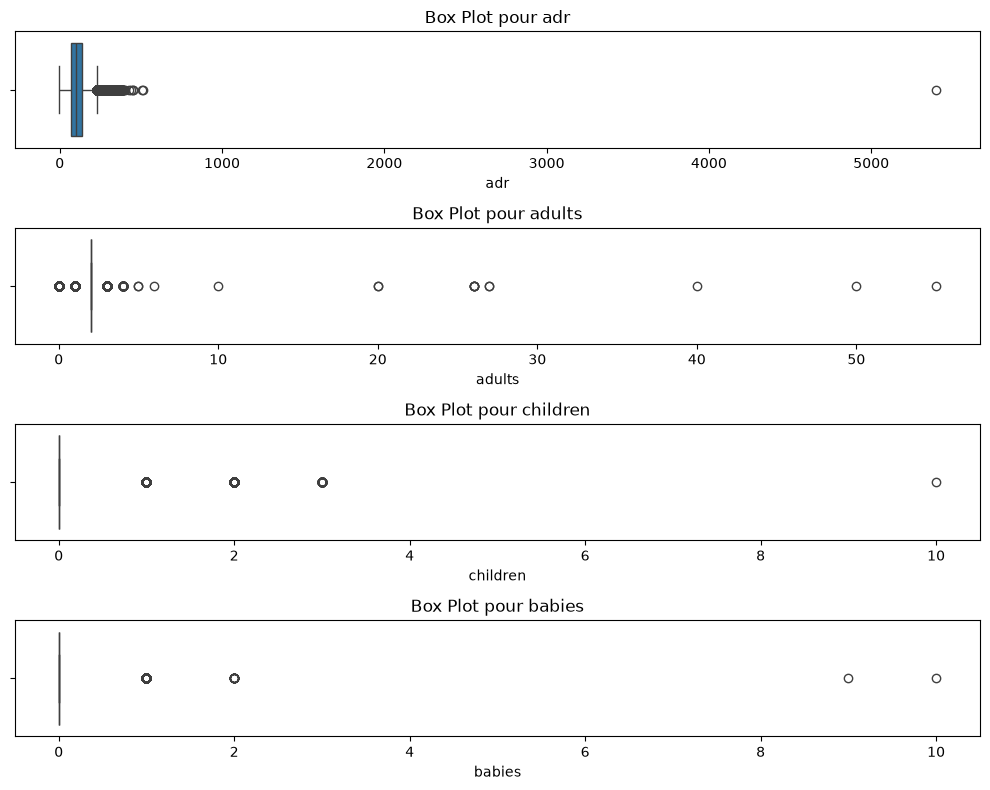

In [10]:
# Détection de "outliers" avec boxplot
detect_outliers_cols = ['adr', 'adults', 'children', 'babies']
no_of_rows = len(detect_outliers_cols)
fig, axes = plt.subplots(no_of_rows, 1, figsize=(10, 2*no_of_rows))
axes = axes.flatten()
for i, col in enumerate(detect_outliers_cols):
    sns.boxplot(data=df, x=col, ax=axes[i])
    axes[i].set_title(f'Box Plot pour {col}')
# Remove unused subplots (if any)
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

### Suppression des valeurs aberrantes
- "adr":
	- Lorsque le prix par nuit est négatif
	- Lorsque le prix par nuit est anormalement élevé: prix moyen et médiane proches de 100 avec un écart type de 50, le maximum est de 5400, on supprime les prix au dessus de 2000
- "adults": Lorsqu'il n'y a aucun adulte
- "children": Lorsqu'il y a plus de 4 enfants
- "babies": Lorsqu'il y a plus de 2 bébés


In [11]:
outliers = pd.DataFrame({
    'Aucun adulte': df['adults'] <= 0,
    'Plus de 4 enfants': df['children'] > 4,
    'Plus de 2 bébés': df['babies'] > 2,
    'Prix négatif (adr < 0)': df['adr'] < 0,
    'Prix par nuit trop élevé': df['adr'] > 2000,
})
print(outliers.sum().to_string(), '\n')
a_supprimer = outliers.any(axis=1)
df = df[~a_supprimer].copy()
print(f'Suppressions: {a_supprimer.sum()} lignes. {len(df):,} réservations restantes.')


Aucun adulte                377
Plus de 4 enfants             1
Plus de 2 bébés               2
Prix négatif (adr < 0)        1
Prix par nuit trop élevé      1 

Suppressions: 382 lignes. 83,006 réservations restantes.


In [ ]:
# Segregate the numerical and categorical columns for specific type of visualization
cont_numerical_cols = ['adr', 'lead_time', 'previous_bookings_not_canceled', 'days_in_waiting_list']
discrete_numerical_cols = ['adults', 'children', 'babies', 'previous_cancellations', 'booking_changes', 
                           'total_of_special_requests', 'required_car_parking_spaces', 'stays_in_weekend_nights', 
                           'stays_in_week_nights']
categorical_cols =['hotel', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 
                   'reserved_room_type', 'deposit_type', 'agent', 'customer_type']
date_cols = ['arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month']
data_leak_cols = ['assigned_room_type', 'reservation_status', 'reservation_status_date']
target = ['is_canceled']

## 2.1. Visualisations

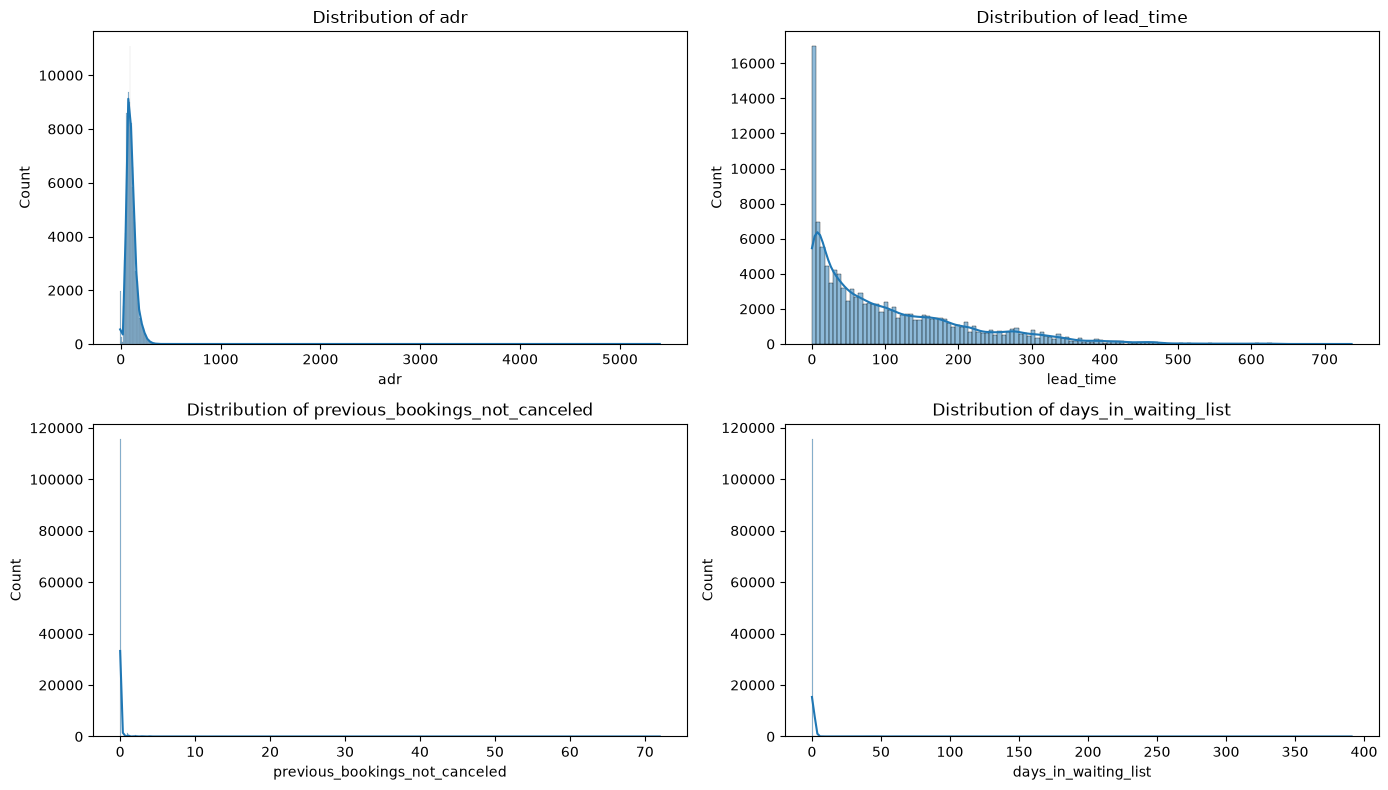

In [5]:
# Visualize the continous numerical columns using Histogram
no_of_rows = int((len(cont_numerical_cols)+1)/2)
fig, axes = plt.subplots(no_of_rows, 2, figsize=(14, 4*no_of_rows))
axes = axes.flatten()
for i, col in enumerate(cont_numerical_cols):
    sns.histplot(data=df, x=col, ax=axes[i], kde=True)
    axes[i].set_title(f'Distribution of {col}')
# Remove unused subplots (if any)
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

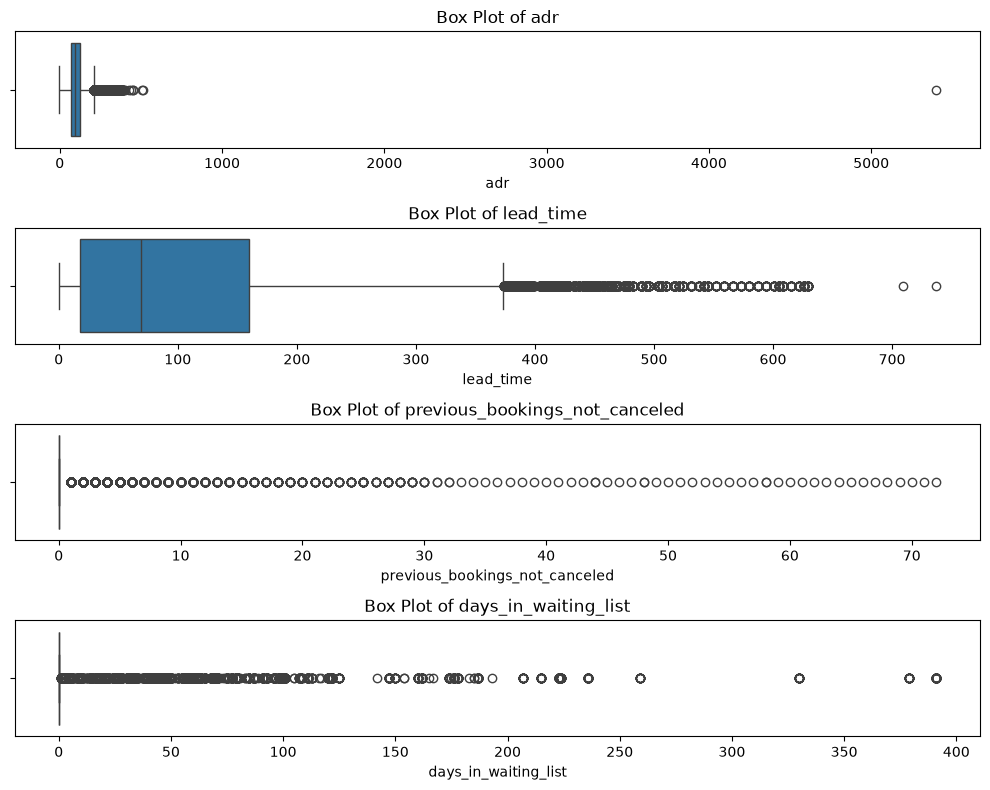

In [6]:
# Detect the outliers using boxplot
no_of_rows = len(cont_numerical_cols)
fig, axes = plt.subplots(no_of_rows, 1, figsize=(10, 2*no_of_rows))
axes = axes.flatten()
for i, col in enumerate(cont_numerical_cols):
    sns.boxplot(data=df, x=col, ax=axes[i])
    axes[i].set_title(f'Box Plot of {col}')
# Remove unused subplots (if any)
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

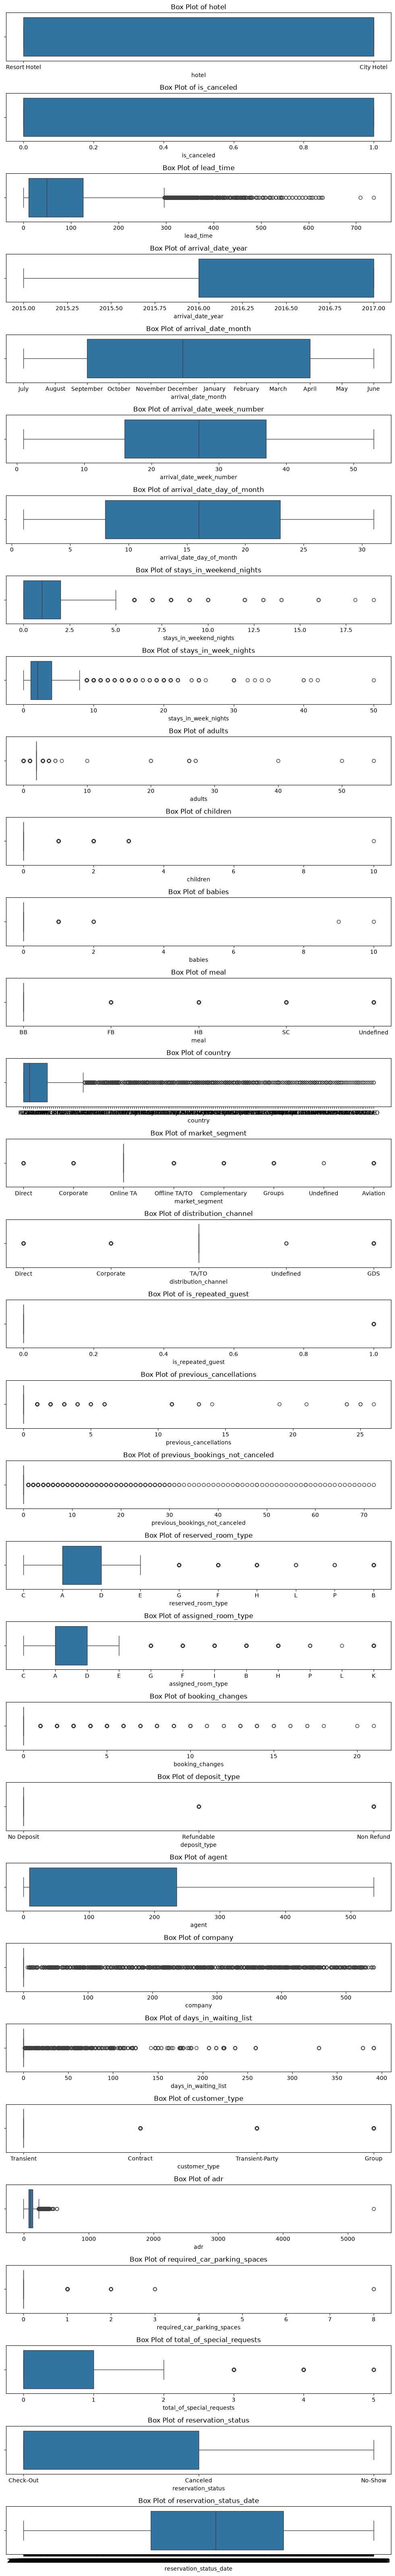

In [14]:
# Detect the outliers using boxplot
no_of_rows = len(df.columns)
fig, axes = plt.subplots(no_of_rows, 1, figsize=(10, 2*no_of_rows))
axes = axes.flatten()
for i, col in enumerate(df.columns):
    sns.boxplot(data=df, x=col, ax=axes[i])
    axes[i].set_title(f'Box Plot of {col}')
# Remove unused subplots (if any)
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

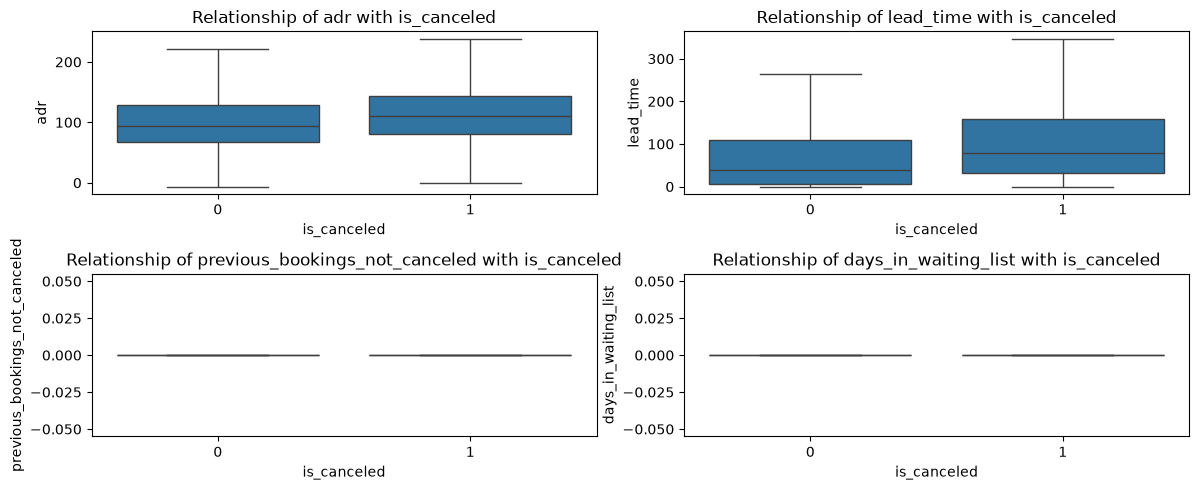

In [11]:
# Visualize the relationship of the numerical colums with the target
no_of_rows = (len(cont_numerical_cols)+1)//2
fig, axes = plt.subplots(no_of_rows, 2, figsize=(12, 5))
axes = axes.flatten()
for i, col in enumerate(cont_numerical_cols):
    sns.boxplot(data=df[cont_numerical_cols+target], x=target[0], y=col, showfliers=False, ax=axes[i])
    axes[i].set_title(f'Relationship of {col} with is_canceled')
# Remove unused subplots (if any)
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

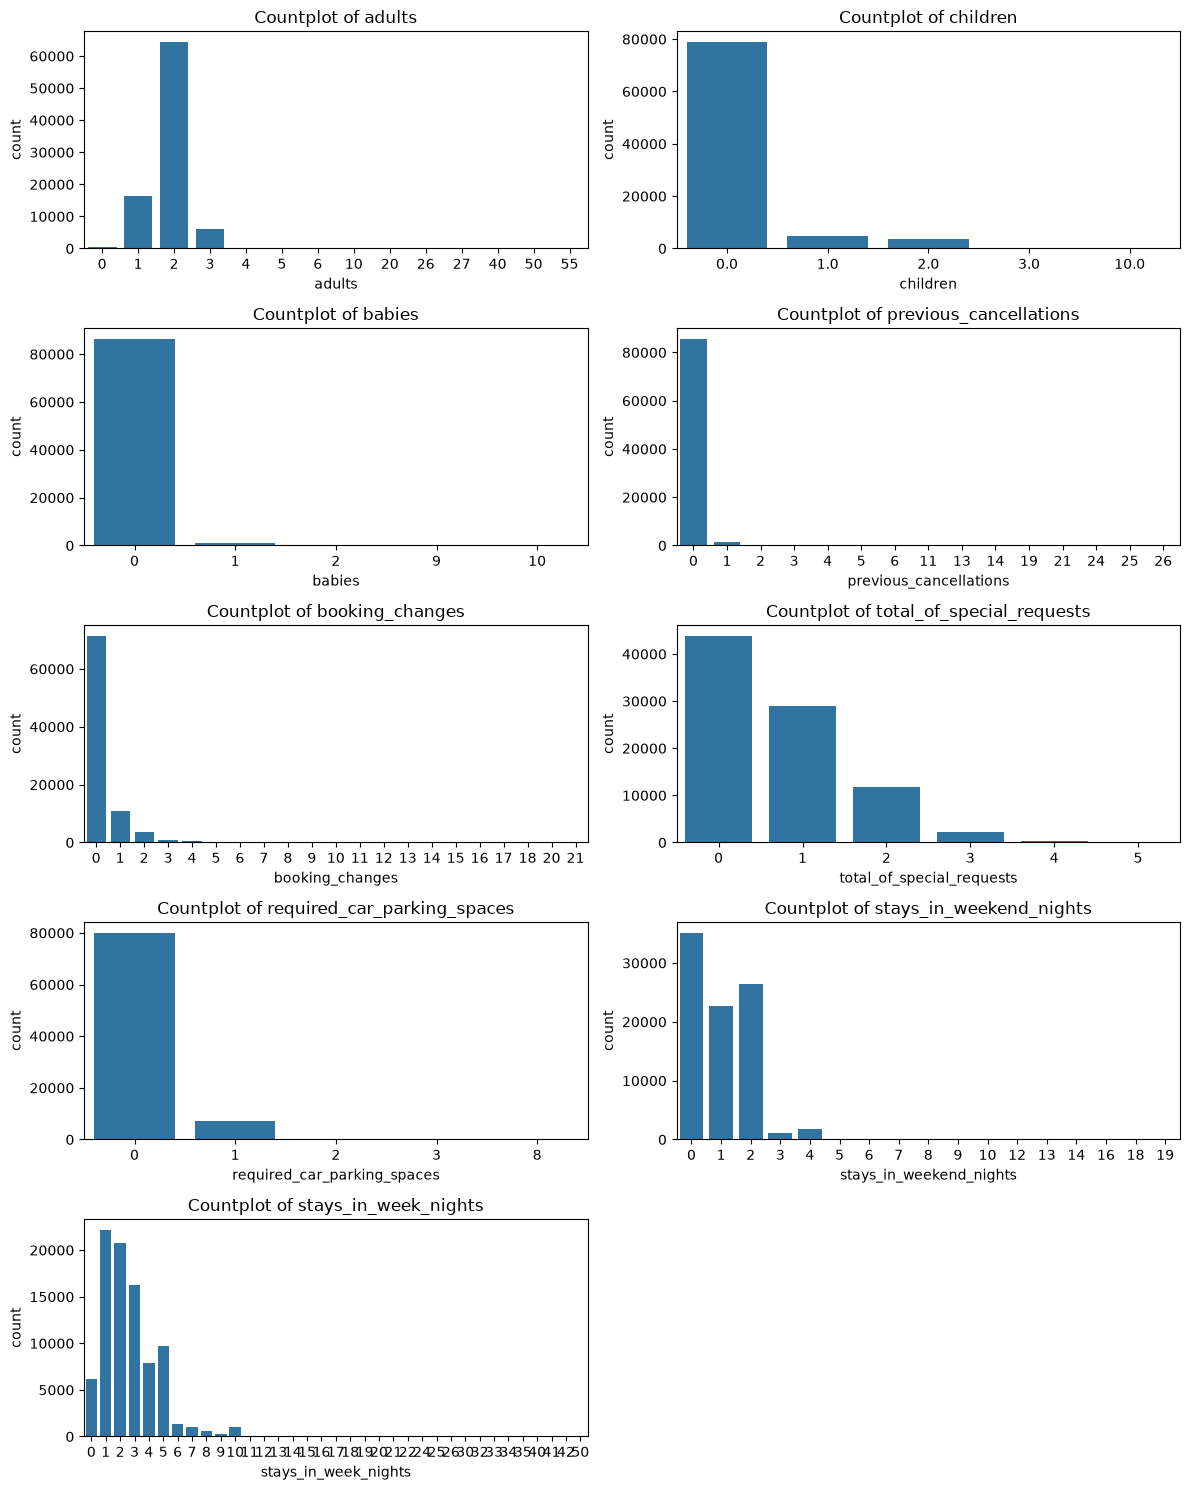

In [12]:
# Visualize the discrete numerical columns using Countplot
no_of_rows = (len(discrete_numerical_cols)+1)//2
fig, axes = plt.subplots(no_of_rows, 2, figsize=(12, 15))
axes = axes.flatten()
for i, col in enumerate(discrete_numerical_cols):
    sns.countplot(data=df, x=col, ax=axes[i])
    axes[i].set_title(f'Countplot of {col}')
# Remove unused subplots (if any)
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

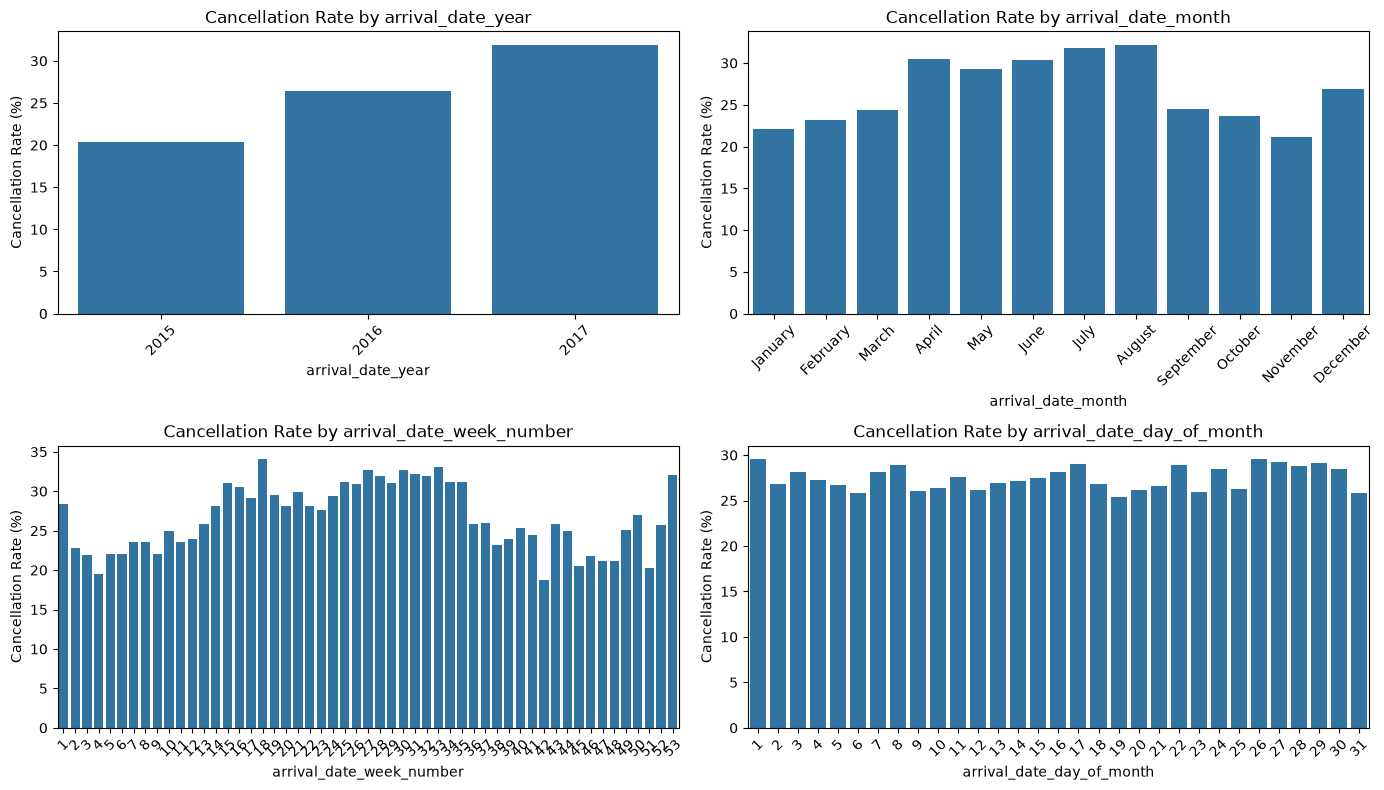

In [13]:
# Visualize cancellation rate for date features
no_of_rows = (len(date_cols) + 1)//2
fig, axes = plt.subplots(no_of_rows, 2, figsize=(14, 4 * no_of_rows))
axes = axes.flatten()
for i, col in enumerate(date_cols):
    cancel_rate = (pd.crosstab(df[col], df['is_canceled'], normalize='index')*100)[1]
    if col == 'arrival_date_month':
        month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 
                       'October', 'November', 'December']
        cancel_rate = cancel_rate.reindex(month_order)
    sns.barplot(x=cancel_rate.index, y=cancel_rate.values, ax=axes[i])
    axes[i].set_title(f'Cancellation Rate by {col}')
    axes[i].set_ylabel('Cancellation Rate (%)')
    axes[i].set_xlabel(col)
    axes[i].tick_params(axis='x', rotation=45)
# Remove unused subplot
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

In [8]:
outliers = pd.DataFrame({
    'Aucun adulte': df['adults'] <= 0,
    'Plus de 4 enfants': df['children'] > 4,
    'Plus de 2 bébés': df['babies'] > 2,
    'Prix négatif (adr < 0)': df['adr'] < 0,
    'Prix par nuit trop élevé': df['adr'] > 2000,
})
print(outliers.sum().to_string(), '\n')
a_supprimer = outliers.any(axis=1)
df = df[~a_supprimer].copy()
print(f'Suppressions: {a_supprimer.sum()} lignes. {len(df):,} réservations restantes.')


Aucun adulte                385
Plus de 4 enfants             1
Plus de 2 bébés               2
Prix négatif (adr < 0)        1
Prix par nuit trop élevé      1 

Suppressions: 390 lignes. 87,006 réservations restantes.


# 3. Préparation des données


## 3.1. Corrélation a priori des colonnes numériques avec l'annulation
On cherche à avoir un aperçu des caractéristiques qui ont la plus forte corrélation avec l'annulation

In [9]:
correlation = df[df.select_dtypes(include=['number']).columns].corr()['is_canceled'].abs().sort_values(ascending = False)
correlation

is_canceled                       1.000000
required_car_parking_spaces       0.184573
lead_time                         0.184263
adr                               0.133118
total_of_special_requests         0.121091
booking_changes                   0.093236
is_repeated_guest                 0.088749
arrival_date_year                 0.088018
stays_in_week_nights              0.083998
adults                            0.082957
company                           0.075333
children                          0.066306
stays_in_weekend_nights           0.061052
previous_bookings_not_canceled    0.052190
previous_cancellations            0.051530
babies                            0.021273
arrival_date_day_of_month         0.005512
days_in_waiting_list              0.004759
arrival_date_week_number          0.001661
agent                             0.000761
Name: is_canceled, dtype: float64

## 3.3. Features engeneering

### 3.3.1. Regroupement de valeurs
- Selon la data card du dataset, la colonne "meal" a 2 valeurs qui ont la même signification: Undefined/SC – no meal package, on remplace donc "Undefined" par "SC"

In [9]:
df['meal'] = df['meal'].replace('Undefined', 'SC') 


In [10]:
#del df_copy["company"]

# Grouper réservations antérieures
#df['total_previous_bookings'] = df['previous_cancellations'] + df['previous_bookings_not_canceled']

# Etiquettage deposit_type
#df['deposit_type'] = df['deposit_type'].replace({'No Deposit':0,
#                                                 'Non Refund':1,
#                                                 'Refundable':2
#						 })


## Visualisations

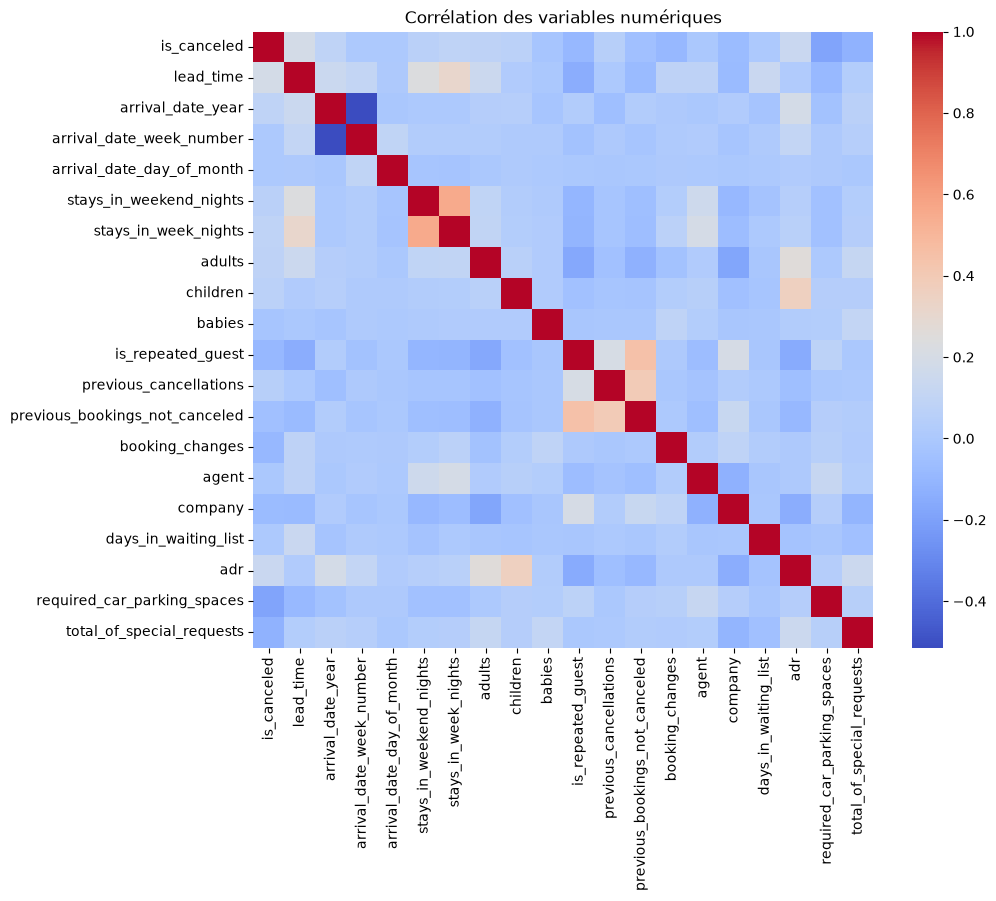

is_canceled                       1.000000
required_car_parking_spaces       0.184573
lead_time                         0.184263
adr                               0.133118
total_of_special_requests         0.121091
booking_changes                   0.093236
is_repeated_guest                 0.088749
arrival_date_year                 0.088018
stays_in_week_nights              0.083998
adults                            0.082957
company                           0.075333
children                          0.066306
stays_in_weekend_nights           0.061052
previous_bookings_not_canceled    0.052190
previous_cancellations            0.051530
babies                            0.021273
arrival_date_day_of_month         0.005512
days_in_waiting_list              0.004759
arrival_date_week_number          0.001661
agent                             0.000761
Name: is_canceled, dtype: float64


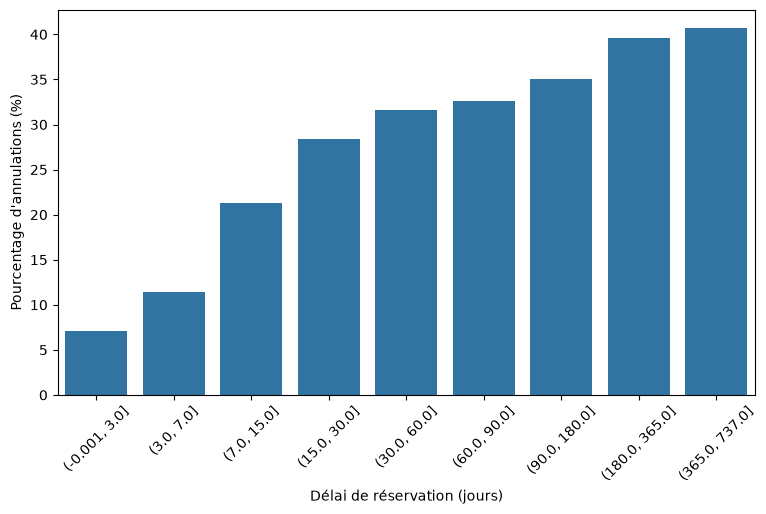

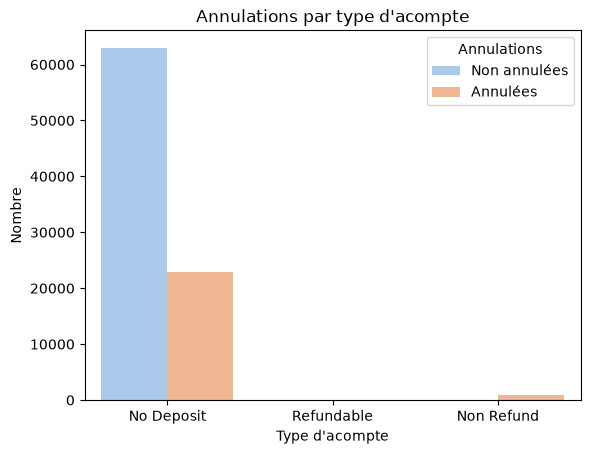

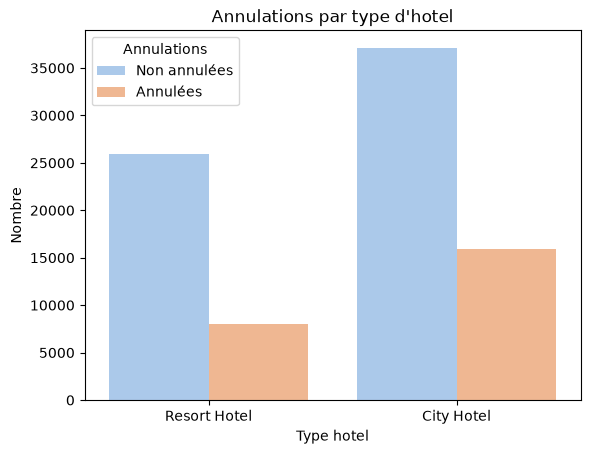

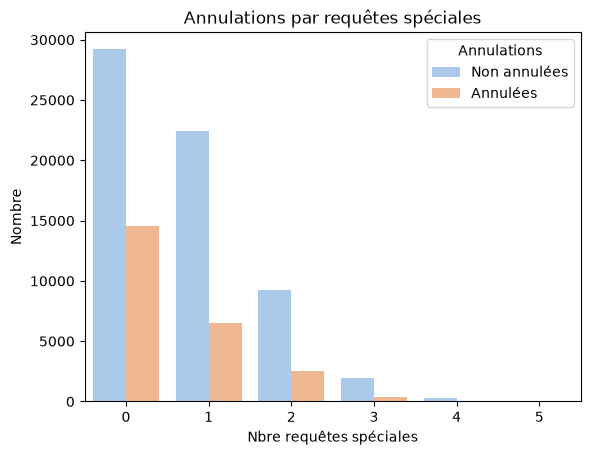

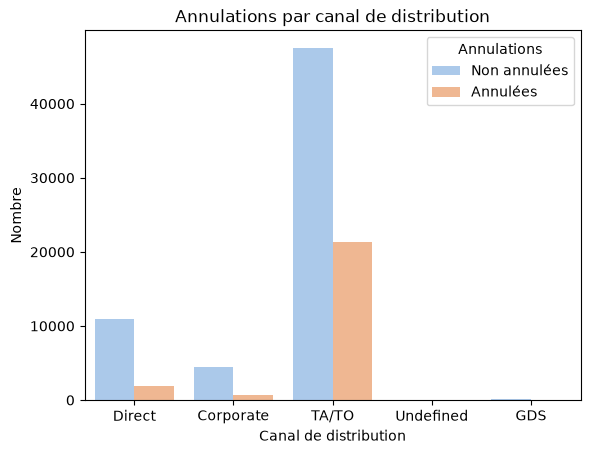

In [10]:
num_cols = df.select_dtypes(include=[np.number]).columns
plt.figure(figsize=(10, 8))
sns.heatmap(df[num_cols].corr(), cmap='coolwarm', annot=False)
plt.title("Corrélation des variables numériques")
plt.show()

correlation = df[df.select_dtypes(include=['number']).columns].corr()['is_canceled'].abs().sort_values(ascending = False)
print(correlation)

# Découpage de lead_time en intervalles
bins = [0, 3, 7, 15, 30, 60, 90, 180, 365, df["lead_time"].max()]
df_lead = df.copy()
df_lead["lead_time_bin"] = pd.cut(df_lead["lead_time"], bins=bins, include_lowest=True)

# Pourcentage d'annulation par intervalle
taux = (df_lead.groupby("lead_time_bin", observed=True)["is_canceled"]
          .mean()
          .mul(100)
          .reset_index())

plt.figure(figsize=(9, 5))
sns.barplot(data=taux, x="lead_time_bin", y="is_canceled")
plt.ylabel("Pourcentage d'annulations (%)")
plt.xlabel("Délai de réservation (jours)")
plt.xticks(rotation=45)
plt.show()

# Courbe lissée sans intervalles
#sns.lineplot(
#    data=df_lead.assign(lead_time_bin=pd.cut(df_lead["lead_time"], bins=40)
#                     .apply(lambda x: x.mid).astype(float)),
#    x="lead_time_bin", y="is_canceled", errorbar=None
#)
#plt.show()

sns.countplot(x="deposit_type", hue="is_canceled", data=df, palette="pastel")
plt.title("Annulations par type d'acompte")
plt.xlabel("Type d'acompte")
plt.ylabel("Nombre")
plt.legend(title="Annulations", labels=["Non annulées", "Annulées"])
plt.show()

sns.countplot(x="hotel", hue="is_canceled", data=df, palette="pastel")
plt.title("Annulations par type d'hotel")
plt.xlabel("Type hotel")
plt.ylabel("Nombre")
plt.legend(title="Annulations", labels=["Non annulées", "Annulées"])
plt.show()

sns.countplot(x="total_of_special_requests", hue="is_canceled", data=df, palette="pastel")
plt.title("Annulations par requêtes spéciales")
plt.xlabel("Nbre requêtes spéciales")
plt.ylabel("Nombre")
plt.legend(title="Annulations", labels=["Non annulées", "Annulées"])
plt.show()

sns.countplot(x="distribution_channel", hue="is_canceled", data=df, palette="pastel")
plt.title("Annulations par canal de distribution")
plt.xlabel("Canal de distribution")
plt.ylabel("Nombre")
plt.legend(title="Annulations", labels=["Non annulées", "Annulées"])
plt.show()



# Séparation caractéristiques (X) et cible (y)

In [11]:
print("\nSéparation des variables explicatives et de la cible...")

# Suppressions colonnes non significativement corrélées
useless_col = ['days_in_waiting_list', 'arrival_date_year', 'assigned_room_type', 'booking_changes',
               'reservation_status', 'country', 'reservation_status_date']
df = df.drop(useless_col, axis = 1)

# Conversion 'arrival_date_month' en valeurs numériques ordonnées
months = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
df['arrival_date_month'] = df['arrival_date_month'].apply(lambda x: months.index(x) + 1)

# Colonnes sur lesquelles faire du One-hot encoding
one_hot_cols = ['hotel', 'meal', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'customer_type']
df = pd.get_dummies(df, columns=one_hot_cols)   #, drop_first=True)

df.info()

#X = df_copy.drop('is_canceled', axis=1)
#y = df_copy['is_canceled']

#X = df_copy[['lead_time','shop_id','week_day','month']].copy()
#numeric_cols = ['sales_partial']
#y = df_copy['is_canceled'].copy()
#
#X.head()


Séparation des variables explicatives et de la cible...
<class 'pandas.DataFrame'>
Index: 87006 entries, 0 to 119389
Data columns (total 53 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   is_canceled                     87006 non-null  int64  
 1   lead_time                       87006 non-null  int64  
 2   arrival_date_month              87006 non-null  int64  
 3   arrival_date_week_number        87006 non-null  int64  
 4   arrival_date_day_of_month       87006 non-null  int64  
 5   stays_in_weekend_nights         87006 non-null  int64  
 6   stays_in_week_nights            87006 non-null  int64  
 7   adults                          87006 non-null  int64  
 8   children                        87006 non-null  float64
 9   babies                          87006 non-null  int64  
 10  is_repeated_guest               87006 non-null  int64  
 11  previous_cancellations          87006 non-null  int

In [12]:
# Définition des caractéristiques (X) et de la sortie etiquetée (y)
X = df.drop('is_canceled', axis=1)
y = df['is_canceled'] 

In [13]:
X.dtypes

lead_time                           int64
arrival_date_month                  int64
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
agent                             float64
company                           float64
adr                               float64
required_car_parking_spaces         int64
total_of_special_requests           int64
hotel_City Hotel                     bool
hotel_Resort Hotel                   bool
meal_BB                              bool
meal_FB                              bool
meal_HB                              bool
meal_SC                              bool
market_segment_Aviation           

In [14]:
print(f"X shape: {X.shape}, y shape: {y.shape}")

X shape: (87006, 52), y shape: (87006,)


In [15]:
# Séparation du dataset en données d'entrainement et de validation
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)

In [18]:
# Regression logistique

## 2. Séparer en ensembles d'entraînement et de test
#_train, X_test, y_train, y_test = train_test_split(
#   X, y, test_size=0.2, random_state=42
#
#
## 3. Normaliser les données (fortement recommandé pour la régression logistique)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
#
## 4. Créer et entraîner le modèle
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)
#
## 5. Faire des prédictions
y_pred = model.predict(X_test_scaled)  # Classes prédites (0 ou 1)
y_proba = model.predict_proba(X_test_scaled)[
    :, 1
]  # Probabilités de la classe 1
#
## 6. Évaluer les performances
print(f"Précision (Accuracy) : {accuracy_score(y_test, y_pred):.2%}")
print("\nRapport détaillé :")
print(classification_report(y_test, y_pred))
display(y_proba)

######

lr = LogisticRegression()
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

acc_lr = accuracy_score(y_test, y_pred_lr)
conf = confusion_matrix(y_test, y_pred_lr)
clf_report = classification_report(y_test, y_pred_lr)

print(f"Accuracy Score of Logistic Regression is : {acc_lr}")
print(f"Confusion Matrix : \n{conf}")
print(f"Classification Report : \n{clf_report}")

Précision (Accuracy) : 78.57%

Rapport détaillé :
              precision    recall  f1-score   support

           0       0.80      0.94      0.86     12617
           1       0.70      0.39      0.50      4785

    accuracy                           0.79     17402
   macro avg       0.75      0.66      0.68     17402
weighted avg       0.77      0.79      0.76     17402



array([0.37696305, 0.06743485, 0.52468866, ..., 0.19636671, 0.29499588,
       0.28103668], shape=(17402,))

Accuracy Score of Logistic Regression is : 0.7801402137685324
Confusion Matrix : 
[[11676   941]
 [ 2885  1900]]
Classification Report : 
              precision    recall  f1-score   support

           0       0.80      0.93      0.86     12617
           1       0.67      0.40      0.50      4785

    accuracy                           0.78     17402
   macro avg       0.74      0.66      0.68     17402
weighted avg       0.77      0.78      0.76     17402



/Users/joel/developpement/AI/Alyra/Projet/Stay-Prediction-ML-part/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [23]:
# Random forest tree

rd_clf = RandomForestClassifier(n_estimators=100, random_state=42)	# n_estimators=100, random_state=42
#rd_clf.fit(X_train, y_train)
rd_clf.fit(X_train_scaled, y_train)

#y_pred_rd_clf = rd_clf.predict(X_test)
y_pred_rd_clf = rd_clf.predict(X_test_scaled)

acc_rd_clf = accuracy_score(y_test, y_pred_rd_clf)
conf = confusion_matrix(y_test, y_pred_rd_clf)
clf_report = classification_report(y_test, y_pred_rd_clf)

print(f"Accuracy Score of Random Forest is : {acc_rd_clf}")
print(f"Confusion Matrix : \n{conf}")
print(f"Classification Report : \n{clf_report}")



Accuracy Score of Random Forest is : 0.8166877370417194
Confusion Matrix : 
[[11566  1051]
 [ 2139  2646]]
Classification Report : 
              precision    recall  f1-score   support

           0       0.84      0.92      0.88     12617
           1       0.72      0.55      0.62      4785

    accuracy                           0.82     17402
   macro avg       0.78      0.73      0.75     17402
weighted avg       0.81      0.82      0.81     17402



In [21]:
# XGboosting
from xgboost import XGBClassifier

xgb = XGBClassifier(booster = 'gbtree', learning_rate = 0.1, max_depth = 5, n_estimators = 180	#, random_state=42
                    )
xgb.fit(X_train, y_train)

y_pred_xgb = xgb.predict(X_test)

acc_xgb = accuracy_score(y_test, y_pred_xgb)
conf = confusion_matrix(y_test, y_pred_xgb)
clf_report = classification_report(y_test, y_pred_xgb)

print(f"Accuracy Score of Ada Boost Classifier is : {acc_xgb}")
print(f"Confusion Matrix : \n{conf}")
print(f"Classification Report : \n{clf_report}")

Accuracy Score of Ada Boost Classifier is : 0.8153660498793243
Confusion Matrix : 
[[11770   847]
 [ 2366  2419]]
Classification Report : 
              precision    recall  f1-score   support

           0       0.83      0.93      0.88     12617
           1       0.74      0.51      0.60      4785

    accuracy                           0.82     17402
   macro avg       0.79      0.72      0.74     17402
weighted avg       0.81      0.82      0.80     17402



In [31]:
# KNN
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=10, weights="uniform")	#, weights="distance")
knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_test_scaled)

acc_knn = accuracy_score(y_test, y_pred_knn)
conf = confusion_matrix(y_test, y_pred_knn)
clf_report = classification_report(y_test, y_pred_knn)

print(f"Accuracy Score of KNN is : {acc_knn}")
print(f"Confusion Matrix : \n{conf}")
print(f"Classification Report : \n{clf_report}")

Accuracy Score of KNN is : 0.7875531548097919
Confusion Matrix : 
[[11687   930]
 [ 2767  2018]]
Classification Report : 
              precision    recall  f1-score   support

           0       0.81      0.93      0.86     12617
           1       0.68      0.42      0.52      4785

    accuracy                           0.79     17402
   macro avg       0.75      0.67      0.69     17402
weighted avg       0.77      0.79      0.77     17402



# Construction Modèle 1

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, precision_score, recall_score, accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

start_rows = len(df)

# --- 1. Fill missing values where the meaning is clear ---
#df['children'] = df['children'].fillna(0).astype(int)     # 4 rows: assume no children
#df['country'] = df['country'].fillna('Unknown')            # keep these bookings, label the country
df['has_agent'] = df['agent'].notna().astype(int)          # 1 = booked through a travel agent
df['has_company'] = df['company'].notna().astype(int)      # 1 = a company booked/paid

# --- 2. Merge labels that mean the same thing ---
#df['meal'] = df['meal'].replace('Undefined', 'SC')         # both mean "no meal package"

# --- 3. Remove impossible rows ---
#guests = df['adults'] + df['children'] + df['babies']
#problems = pd.DataFrame({
#    'No guests at all': guests == 0,
#    'Negative price (adr < 0)': df['adr'] < 0,
#    'Price over 1,000 per night': df['adr'] > 1000,
#})
#print(problems.sum().to_string(), '\n')
#bad = problems.any(axis=1)
#df = df[~bad].copy()
#print(f'Removed {bad.sum()} rows ({bad.sum() / start_rows:.2%}). {len(df):,} bookings left.')


# --- 4. Add helpful columns ---
df['arrival_date'] = pd.to_datetime(
    df['arrival_date_year'].astype(str) + '-' + df['arrival_date_month'] + '-'
    + df['arrival_date_day_of_month'].astype(str), format='%Y-%B-%d')


NUMERIC = ['lead_time', 'arrival_date_week_number', 'stays_in_weekend_nights', 'stays_in_week_nights',
           'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations',
           'previous_bookings_not_canceled', 'days_in_waiting_list', 'adr', 'total_of_special_requests',
           'has_agent', 'has_company']
CATEGORICAL = ['hotel', 'arrival_date_month', 'meal', 'market_segment', 'distribution_channel',
               'reserved_room_type', 'deposit_type', 'customer_type']
FEATURES = NUMERIC + CATEGORICAL

train = df[df['arrival_date'] < '2017-01-01']
test = df[df['arrival_date'] >= '2017-01-01']
print(f'Train: {len(train):,} bookings (Jul 2015 - Dec 2016), {train.is_canceled.mean():.0%} cancelled')
print(f'Test:  {len(test):,} bookings (Jan - Aug 2017), {test.is_canceled.mean():.0%} cancelled')


def make_model(estimator, numeric=NUMERIC, categorical=CATEGORICAL):
    """Pipeline = prepare the columns, then fit the model. Same steps for train and test, no mix-ups."""
    prep = ColumnTransformer([
        ('num', StandardScaler(), numeric),                                     # put numbers on the same scale
        ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=50,
                              sparse_output=False), categorical),               # text -> 0/1 columns
    ])
    return Pipeline([('prep', prep), ('model', estimator)])


models = {
    'Logistic regression': make_model(LogisticRegression(max_iter=3000)),
    'Gradient boosting': make_model(HistGradientBoostingClassifier(random_state=42)),
}
scores = {}
for name, model in models.items():
    model.fit(train[FEATURES], train['is_canceled'])
    scores[name] = model.predict_proba(test[FEATURES])[:, 1]
    print(f'{name:20s} AUC on 2017 = {roc_auc_score(test.is_canceled, scores[name]):.3f}')

No guests at all              180
Negative price (adr < 0)        1
Price over 1,000 per night      1 

Removed 182 rows (0.15%). 119,208 bookings left.
Train: 78,589 bookings (Jul 2015 - Dec 2016), 36% cancelled
Test:  40,619 bookings (Jan - Aug 2017), 39% cancelled
Logistic regression  AUC on 2017 = 0.807
Gradient boosting    AUC on 2017 = 0.825


In [70]:
k=0
for ligne in test.itertuples():
	#print(f"Index= {ligne.Index}, is_canceled={ligne.is_canceled}, hotel={ligne.hotel}")
	data_test = test.iloc[[k]].copy()
	#print(data_test)
	if ligne.is_canceled == 1 :
		prediction = models['Logistic regression'].predict(data_test)
		if prediction[0] == 1 :
			break
	k = k+1
	#if k>20:
	#	break
	#display(data_test.iloc[[0]])
	#print(i, ": is_canceled=", data_test.iloc[[0]]['is_canceled'].item)
	#if ligne.is_canceled == 1 :
	#	print("is_canceled a index ", ligne.Index)
	#	data_test = test.loc[[ligne.Index]].copy()
	#	break

print(f"k={k}")
display(data_test)
#prediction = models['Logistic regression'].predict(data_test)
print(f"Prédiction: {prediction[0]}\n")
display(prediction)



k=64


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,has_agent,has_company,arrival_date
9839,Resort Hotel,1,322,2017,January,2,10,16,40,2,...,0,Transient,25.5,0,0,Canceled,2016-10-31,1,0,2017-01-10


Prédiction: 1



array([1])

# Construction modèle 2

In [13]:
NUMERIC = ['lead_time', 'arrival_date_week_number', 'stays_in_weekend_nights', 'stays_in_week_nights',
           'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations',
           'previous_bookings_not_canceled', 'days_in_waiting_list', 'adr', 'total_of_special_requests',
           'has_agent', 'has_company']
CATEGORICAL = ['hotel', 'meal', 'market_segment', 'distribution_channel',
               'reserved_room_type', 'deposit_type', 'customer_type']
FEATURES = NUMERIC + CATEGORICAL

# Split train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (95512, 32) Test: (23878, 32)


In [15]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer()),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessing = ColumnTransformer([
    ("num", numeric_pipeline, NUMERIC),
    ("cat", categorical_pipeline, CATEGORICAL)
])

In [16]:
def create_features(df):
    
    df = df.copy()
    
    # taille de la famille
    df["family_size"] = df["adults"] + df["children"]+ df["babies"]
    
    # personne seule ou non
    df["is_alone"] = (df["family_size"] == 1).astype(int)
    
    
    return df

pipe_logreg = Pipeline([
    
    ("features", FunctionTransformer(create_features)),
    
    ("preprocess", preprocessing),
    
    ("model", LogisticRegression(max_iter=5000))
])

In [17]:
# séparation jeu de validation pour tuning hyperparamètres
print("Before split:", X_train.shape)

X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2,
    stratify=y_train,
    random_state=42
)

print("After split:", X_train_sub.shape, "Validation:", X_val.shape)

Before split: (95512, 32)
After split: (76409, 32) Validation: (19103, 32)


In [18]:
# Validation croisée en 5 folds
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [19]:
grid_logreg = GridSearchCV(
    
    estimator=pipe_logreg,
    
    param_grid={
        "model__C": [0.01, 0.1, 1, 10],
        "preprocess__num__imputer__strategy": ["mean", "median"],
    },
    
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

grid_logreg.fit(X_val, y_val)

print("Best params:", grid_logreg.best_params_)
print("Best CV score:", grid_logreg.best_score_)

ValueError: 
All the 40 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
17 fits failed with the following error:
Traceback (most recent call last):
  File "/Users/joel/developpements/Alyra AI/Projet Bloc 5/.venv/lib/python3.11/site-packages/sklearn/utils/_indexing.py", line 411, in _get_column_indices
    return [column_names.index(col) for col in selected_columns]
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/joel/developpements/Alyra AI/Projet Bloc 5/.venv/lib/python3.11/site-packages/sklearn/utils/_indexing.py", line 411, in <listcomp>
    return [column_names.index(col) for col in selected_columns]
            ^^^^^^^^^^^^^^^^^^^^^^^
ValueError: 'has_agent' is not in list

The above exception was the direct cause of the following exception:

Trace